# 05 — Exploratory data analysis

**Question.** Does PM2.5 pollution show up in what people search for, and how does that differ between Bangkok, Kraków and Melbourne?

This notebook looks at the data before any modelling. It works through five layers, each answering a question the later analysis depends on:

1. **Data quality** — what is missing, and which series are usable?
2. **One variable at a time** — how is PM2.5 distributed, and where are the outliers?
3. **Structure in time** — seasonality, memory, and decomposition.
4. **Two variables** — how search moves with PM2.5, and at what lag.
5. **Many variables** — what the search terms share, and what kinds of week exist.

All figures are drawn by `aqs.plots` with one shared theme. **Colour always means the city** (Bangkok blue, Kraków orange, Melbourne green), PM2.5 is always grey, and no figure uses two y-axes.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import pandas as pd
from scipy import stats
from aqs import features as F, plots as P
from aqs.config import CITIES, HEADLINE_TERMS, INTERIM, WHO_24H_GUIDELINE

P.use_theme()
long, pm25 = F.load_long(), F.load_pm25()
print(f"{len(pm25)} city-weeks of PM2.5, {long.groupby(['city', 'geo_level', 'term']).ngroups} search series")

380 city-weeks of PM2.5, 27 search series


## 1. Data quality

### 1.1 Sensor selection and coverage

PM2.5 comes from every OpenAQ sensor within 25 km of each city centre. A sensor joins the city panel only if it is a reference-grade monitor with valid data on at least half of the study days; low-cost community sensors are excluded because they join part-way through and would shift the city average for reasons unrelated to air quality. The table counts what was found and what was kept.

In [2]:
sel = pd.read_csv(INTERIM / "sensor_selection.csv")
quality = sel.groupby("city").agg(candidate_sensors=("sensor_id", "size"),
                                  kept=("decision", lambda d: (d == "kept").sum()))
quality["weeks_with_data"] = pm25.groupby("city").size()
quality["weeks_in_window"] = 156
quality["coverage_%"] = (quality["weeks_with_data"] / 156 * 100).round(0).astype(int)
quality["median_PM2.5"] = pm25.groupby("city")["pm25_mean"].median().round(1)
quality

,candidate_sensors,kept,weeks_with_data,weeks_in_window,coverage_%,median_PM2.5
city,,,,,,
bangkok,182,64,150,156,96,22.1
krakow,5,2,134,156,86,14.9
melbourne,25,8,96,156,62,5.6


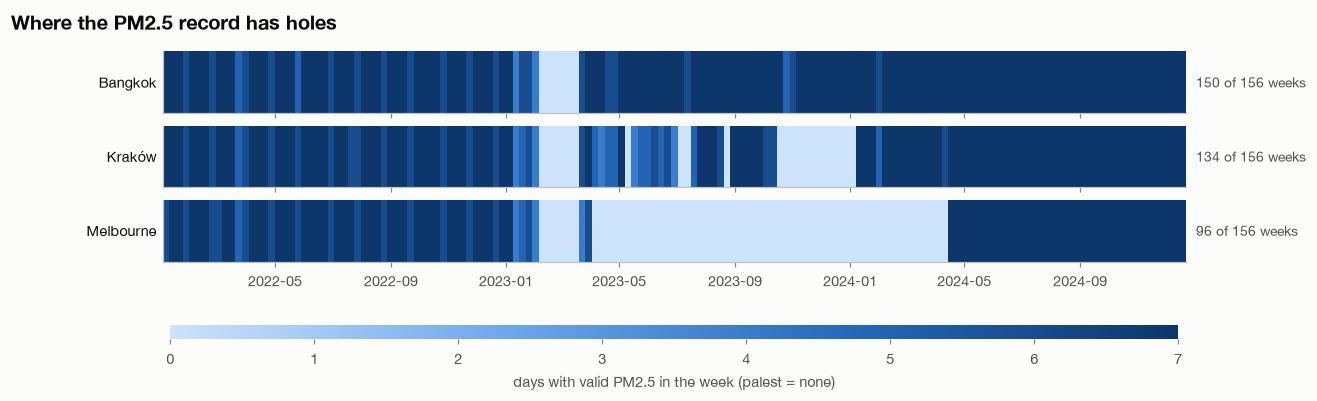

In [3]:
P.coverage_strips(pm25);

**Reading it.** All three cities lose the same six weeks in February–March 2023: that hole is in OpenAQ itself, not in any one monitoring network. Kraków has further gaps in 2023 and Melbourne is missing about a year. Every later method has to cope with these gaps rather than paper over them, so correlations at a lag are computed on a regular weekly index, where weeks on either side of a hole are never paired up.

### 1.2 Which search series are usable

Google Trends reports relative interest from 0 to 100. A term that few people search for is mostly zeros, and a series that is mostly zeros cannot be treated as a continuous measurement.

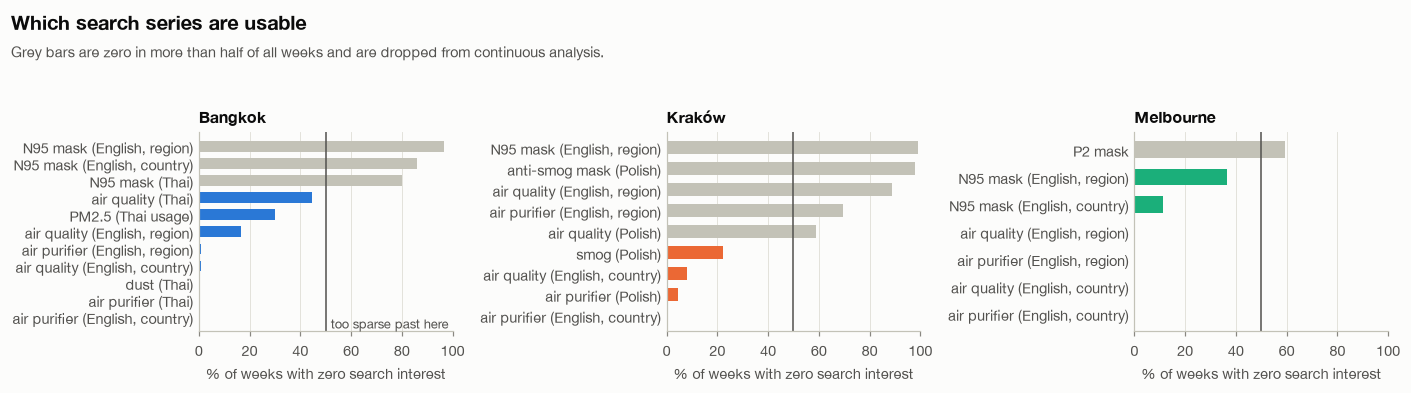

In [4]:
P.zero_inflation(long);

**Reading it.** Mask searches are close to empty in every city, in English and in the local language. English terms are sparse at city-region level in Kraków. The local-language terms are the dense ones — Thai "dust" and "air purifier", Polish "smog" and "air purifier" — so those become each city's headline series. Series above the 50% line are dropped from everything that follows.

The headline series were chosen on this density, before looking at how well any of them tracks PM2.5.

In [5]:
pd.DataFrame({c: {r: F.term_label(c, t) for r, t in HEADLINE_TERMS[c].items()} for c in CITIES}).T

,awareness,protection
bangkok,dust (Thai),air purifier (Thai)
krakow,smog (Polish),air purifier (Polish)
melbourne,"air quality (English, region)","air purifier (English, region)"


## 2. One variable at a time

### 2.1 Shape of the PM2.5 distribution

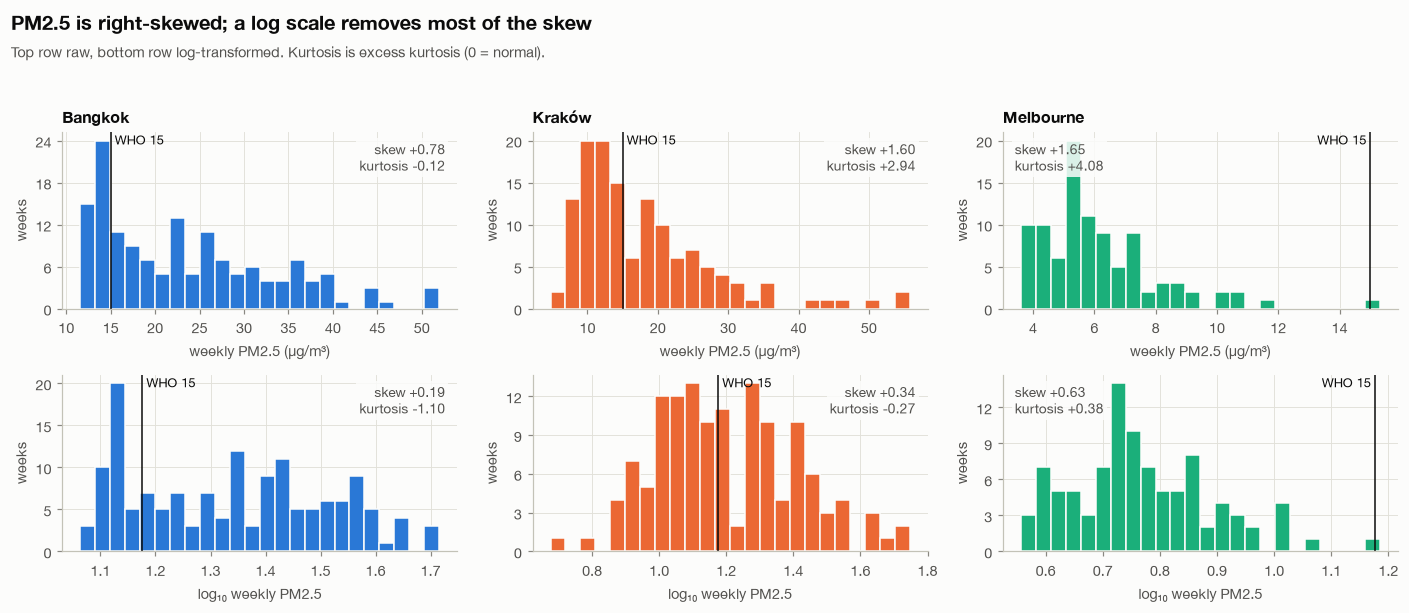

In [6]:
P.distributions(pm25);

In [7]:
shape = pm25.groupby("city")["pm25_mean"].agg(
    mean="mean", median="median", std="std",
    iqr=lambda x: x.quantile(.75) - x.quantile(.25),
    skew=stats.skew, kurtosis=stats.kurtosis,
    pct_above_WHO=lambda x: (x > WHO_24H_GUIDELINE).mean() * 100).round(2)
shape

,mean,median,std,iqr,skew,kurtosis,pct_above_WHO
city,,,,,,,
bangkok,23.72,22.05,9.76,15.24,0.78,-0.12,74.00
krakow,18.02,14.92,9.74,10.89,1.60,2.94,50.00
melbourne,6.15,5.60,1.98,2.11,1.65,4.08,1.04


**Reading it.** Weekly PM2.5 is right-skewed in all three cities: most weeks are ordinary and a few are very bad. The mean sits above the median everywhere, which is why later sections prefer medians and rank-based statistics. A log transform removes most of the skew.

### 2.2 Three pollution regimes

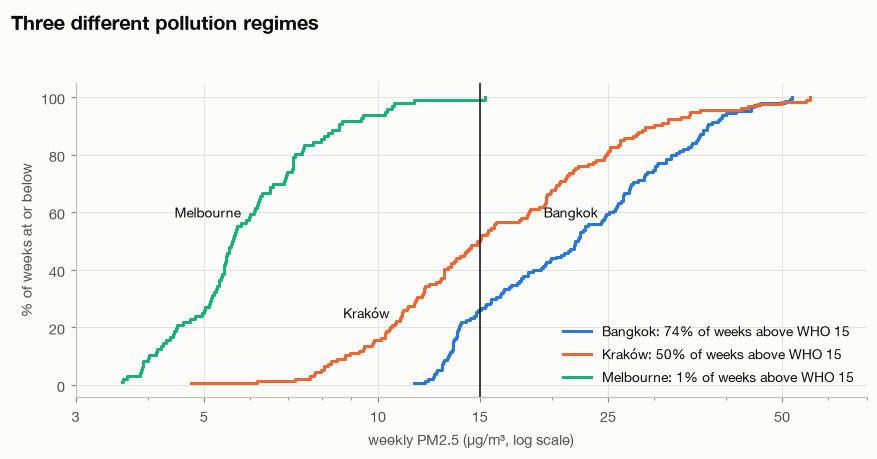

In [8]:
P.ecdf(pm25);

**Reading it.** The cumulative curves barely overlap. Bangkok is above the WHO 24-hour guideline in roughly three weeks out of four, Kraków in half, and Melbourne almost never. This is the contrast the study design relies on: a heavily polluted city, a seasonally polluted one, and a clean baseline.

### 2.3 Normality check

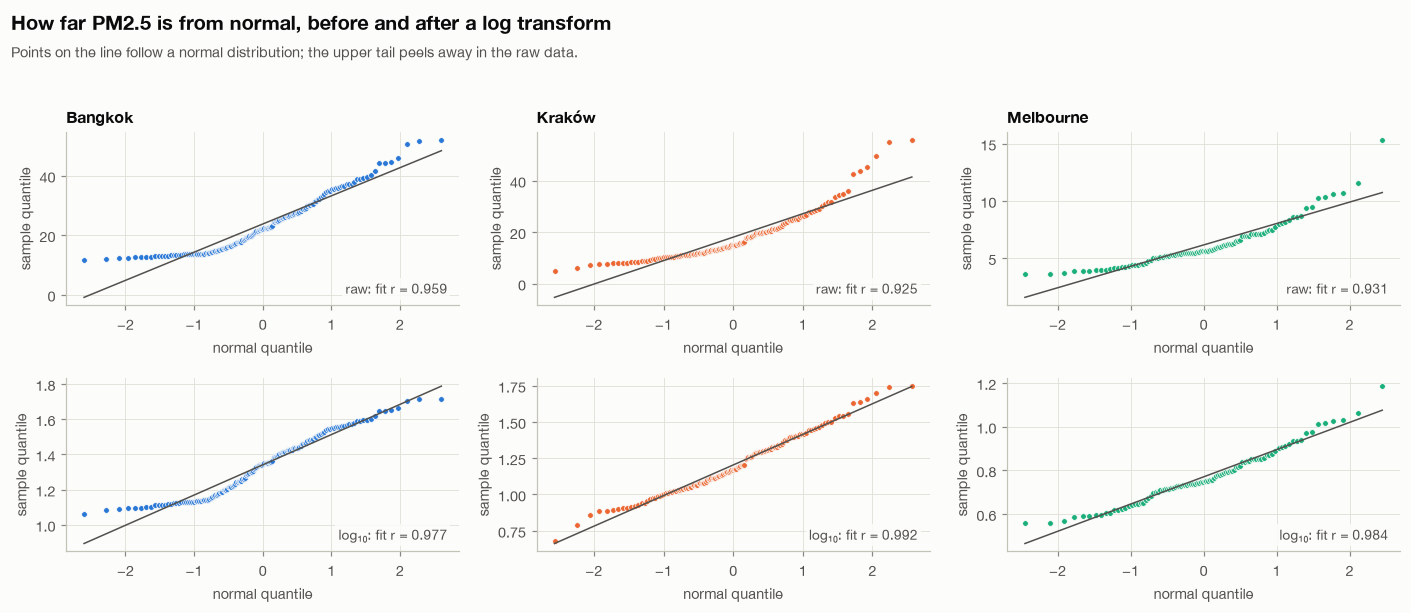

In [9]:
P.qq_plots(pm25);

**Reading it.** In the raw data the upper tail lifts away from the line. After the log transform the points sit much closer to it, most clearly for Kraków. Pearson correlation and ANOVA assume roughly normal data, so this is the evidence for reporting rank-based statistics alongside them.

### 2.4 Outliers that the season does not explain

A week of 40 µg/m³ is routine in a Bangkok January and extraordinary in a Bangkok July. So an outlier is defined relative to its own month: subtract the usual level for that month, then flag weeks more than three robust standard deviations (median absolute deviation) above it.

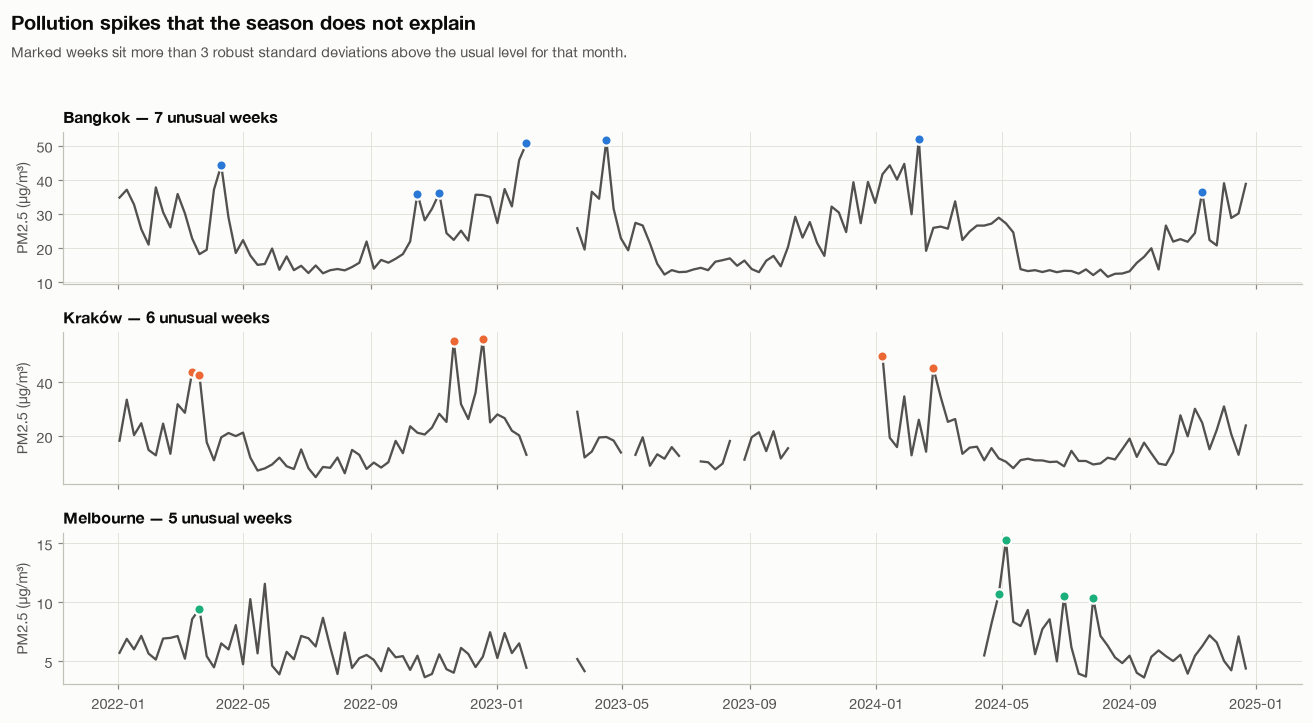

In [10]:
P.outlier_timeline(pm25);

**Reading it.** Each city has a handful of weeks that are unusual even for their season. These are the natural experiments of the project: if the public notices pollution, these are the weeks when search should jump.

## 3. Structure in time

### 3.1 The seasonal calendar

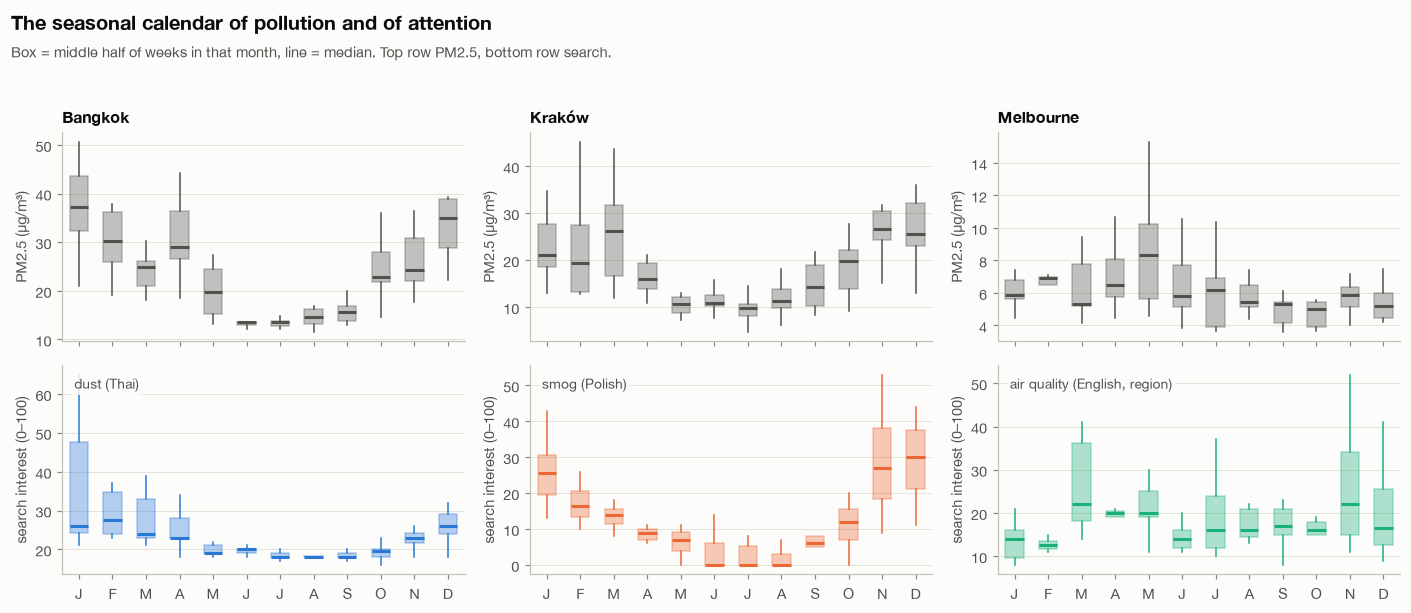

In [11]:
P.seasonal_profile(long);

**Reading it.** Bangkok's pollution peaks in the dry season (December–April) and Kraków's in the heating season (November–March); search follows the same calendar in both. Melbourne has no comparable season in either series. This shared calendar is the main threat to any correlation between the two: both can rise in January without one causing the other.

### 3.2 Week-by-week calendars

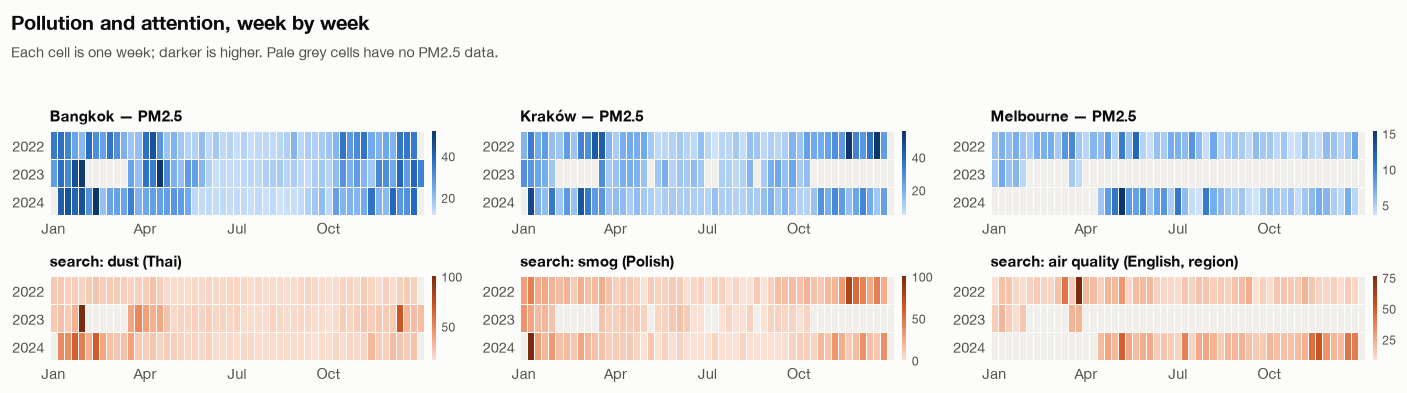

In [12]:
P.calendar_heatmaps(long);

**Reading it.** Reading down a column compares the same week across years. The pollution rows show a broad dark band each season; the search rows show short dark bursts inside that band. Attention is spikier than pollution.

### 3.3 Memory: autocorrelation

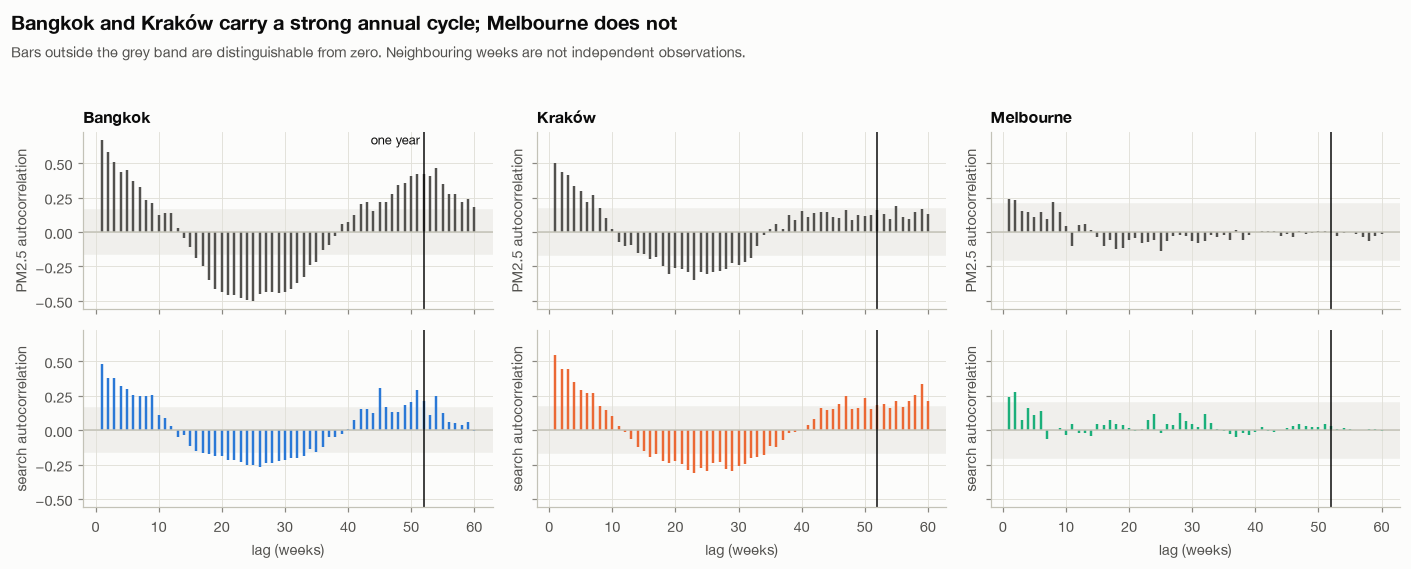

In [13]:
P.autocorrelation(long);

**Reading it.** In Bangkok and Kraków both series stay correlated with themselves for about ten weeks, turn negative half a year out, and return at one year. Two consequences: neighbouring weeks are not independent, so ordinary p-values overstate the evidence; and the annual cycle has to be removed before correlating the two series.

### 3.4 Decomposition

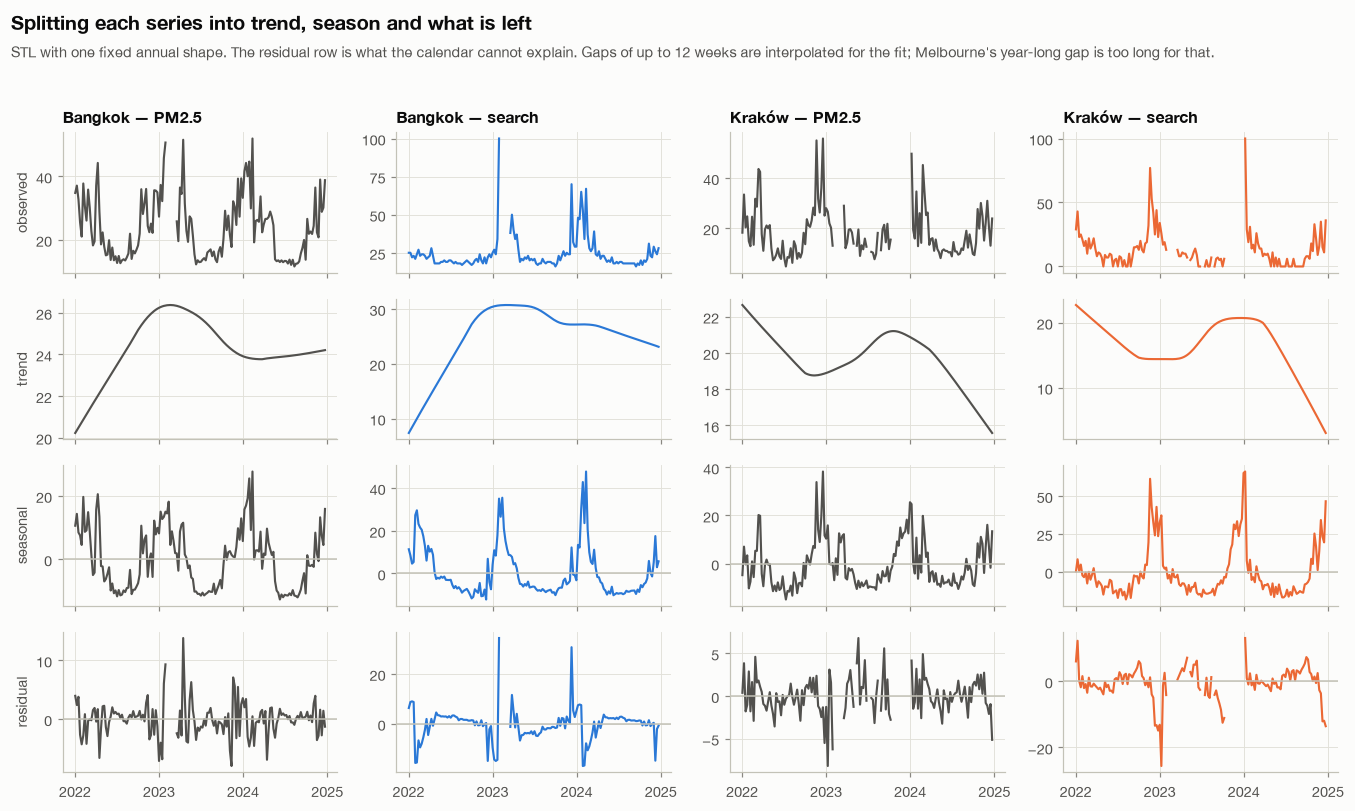

In [14]:
P.stl_decomposition(long);

**Reading it.** The seasonal row carries most of the movement in both series. The residual row is what is left once the calendar is removed, and it is the part that can show whether search responds to pollution itself.

A method note: with only three years of data, the default STL settings let the seasonal shape change every year, which absorbs nearly all the variation and leaves an almost empty residual. The decomposition here forces a single annual shape instead.

## 4. Two variables

### 4.1 Shape of the relationship

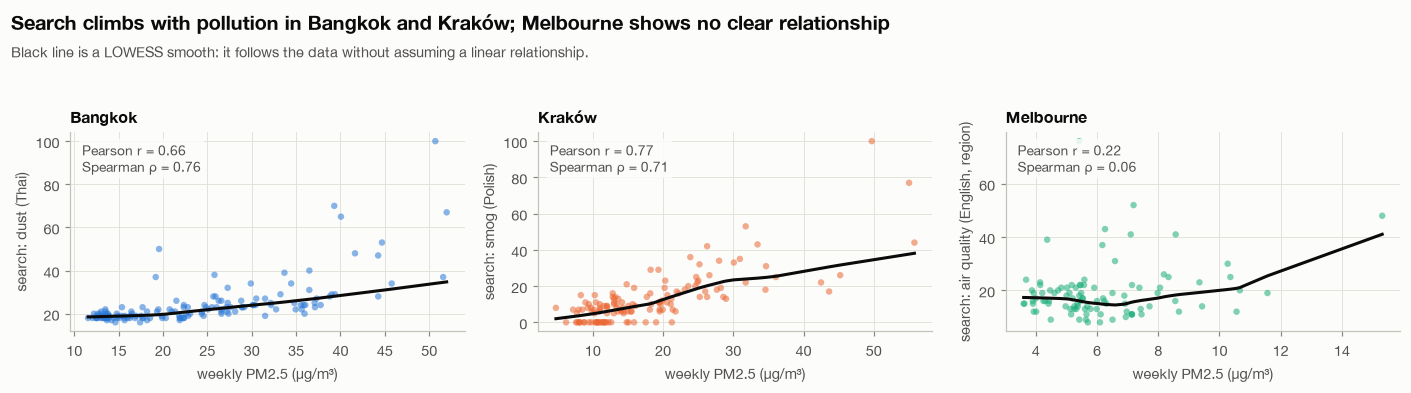

In [15]:
P.scatter_lowess(long);

**Reading it.** In Bangkok and Kraków search climbs with PM2.5, and the spread widens at high pollution: some bad weeks draw enormous attention and others very little. In Kraków the smoothed line is flat at low pollution and rises once PM2.5 passes the low teens, a first hint of a threshold. Melbourne shows no clear relationship; its upturn rests on a single week.

### 4.2 Linear versus rank correlation, every usable series

,city,label,pearson,spearman
0,bangkok,"air purifier (English, country)",0.58,0.73
1,bangkok,"air quality (English, country)",0.65,0.77
2,bangkok,"air purifier (English, region)",0.63,0.66
3,bangkok,air purifier (Thai),0.60,0.69
4,bangkok,"air quality (English, region)",0.76,0.78
5,bangkok,air quality (Thai),0.50,0.45
6,bangkok,dust (Thai),0.66,0.76
7,bangkok,PM2.5 (Thai usage),0.75,0.82
8,krakow,"air purifier (English, country)",0.62,0.60
9,krakow,"air quality (English, country)",0.58,0.56


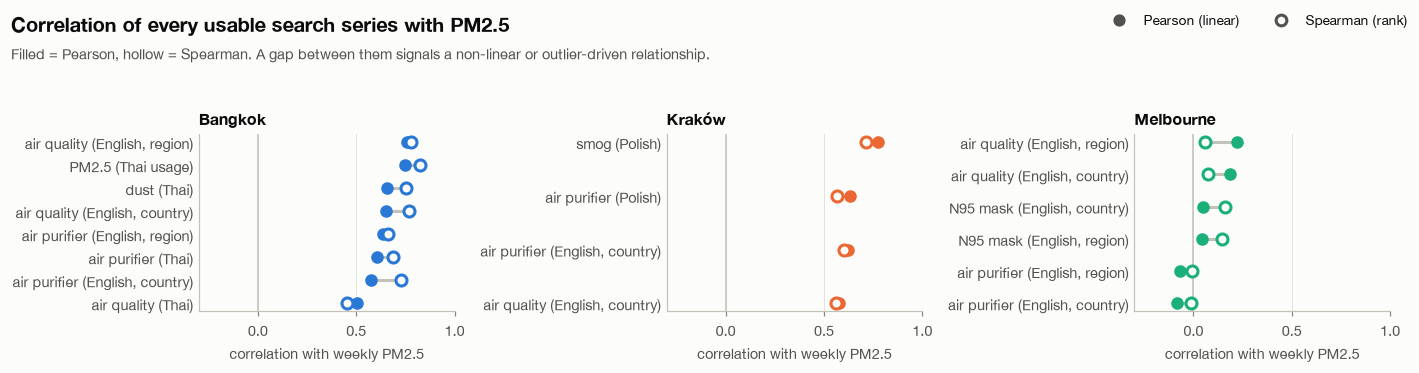

In [16]:
fig, corr = P.pearson_vs_spearman(long)
corr.round(2)

**Reading it.** Every usable series in Bangkok and Kraków correlates with PM2.5 at about 0.5 to 0.8; in Melbourne nothing does. Where Spearman exceeds Pearson (most Bangkok series) the relationship is monotonic but not linear. These are raw correlations and still contain the shared season.

### 4.3 Is the relationship stable through time?

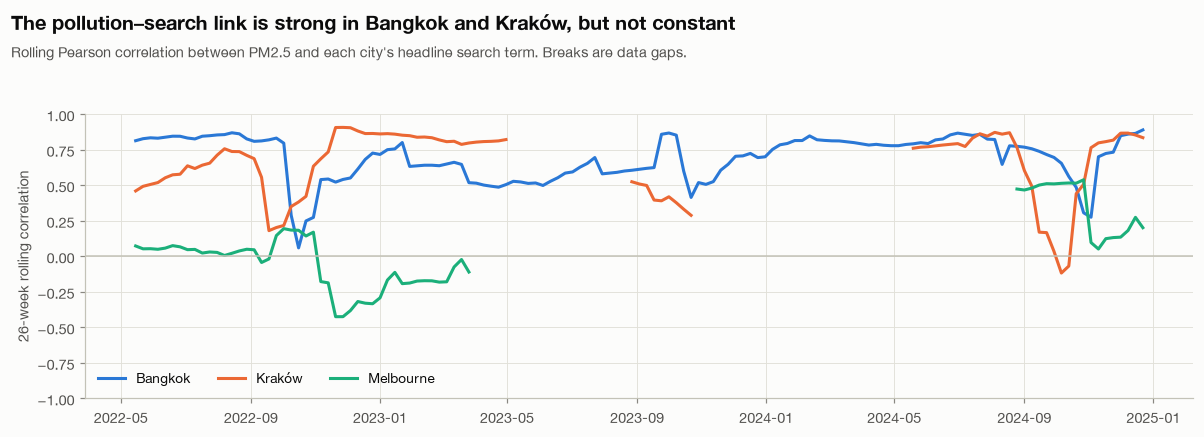

In [17]:
P.rolling_correlations(long);

**Reading it.** Over any half-year window the Bangkok and Kraków correlations are usually high, but they drop sharply for stretches. A single correlation coefficient for the whole period hides that.

### 4.4 Lead and lag

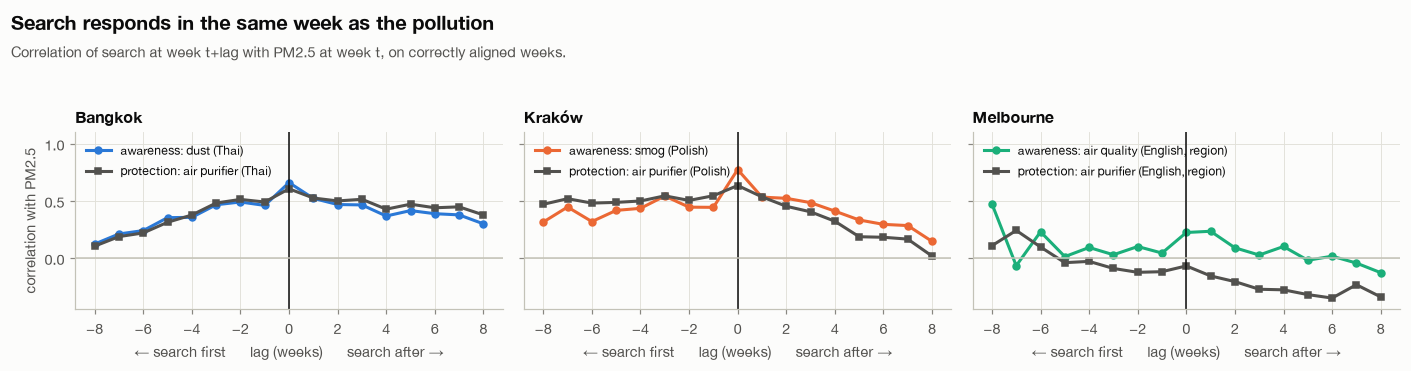

In [18]:
P.lag_profiles(long);

**Reading it.** In Bangkok and Kraków the correlation peaks at lag zero: search responds in the same week as the pollution. An earlier version of this project reported a one-week lead, which came from search weeks being labelled seven days early; with the weeks aligned it disappears.

The curves are broad rather than sharp because both series are seasonal, so the correlation stays high several weeks either side.

## 5. Many variables

### 5.1 How the search terms relate to each other

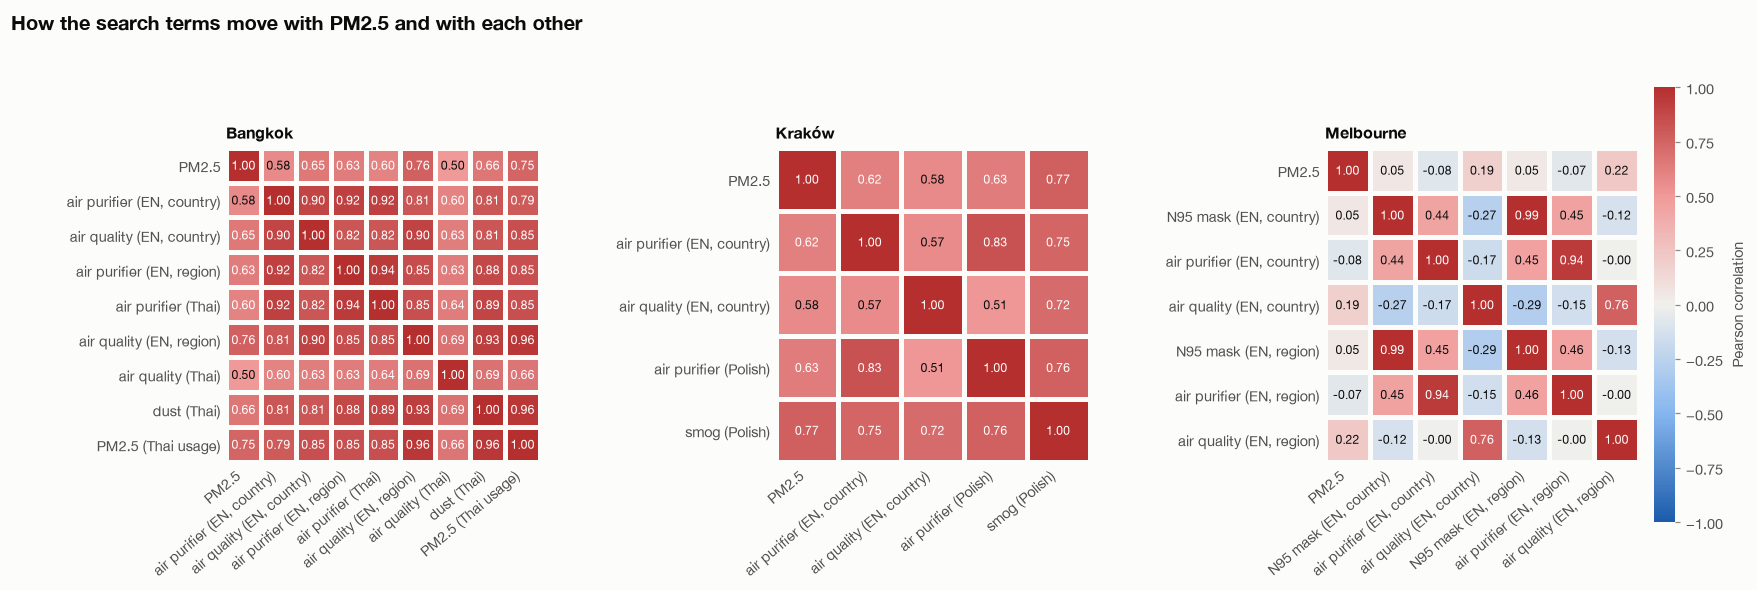

In [19]:
P.correlation_heatmaps(long);

**Reading it.** In Bangkok most search terms correlate with each other at 0.8 to 0.96 — more strongly than any of them correlates with PM2.5. They are largely measuring one thing. In Melbourne the terms split into unrelated groups (mask searches, purifier searches, air-quality searches).

### 5.2 A single attention index (PCA)

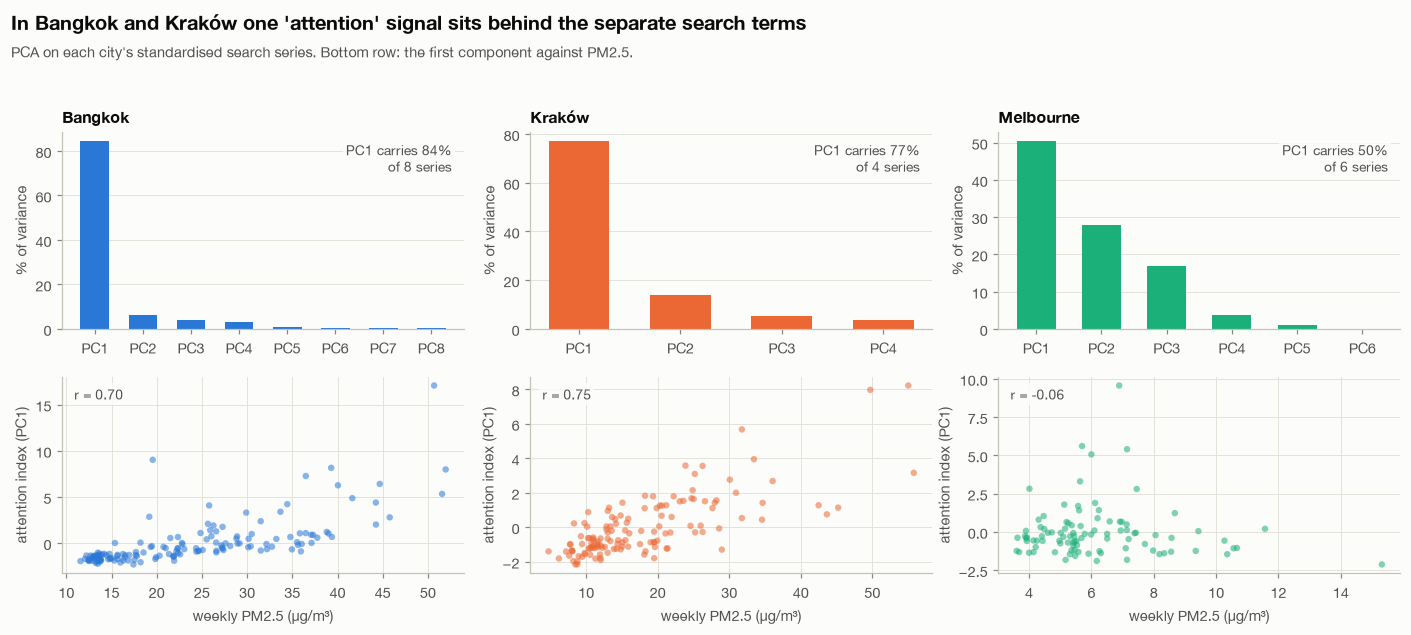

In [20]:
P.pca_summary(long);

**Reading it.** The first principal component carries 84% of the variance of Bangkok's eight search series and 77% of Kraków's four. That component is used as a single **attention index** per city, which avoids picking one favourite term. In Melbourne the first component carries only half the variance and is unrelated to PM2.5.

### 5.3 What kinds of week are there? (clustering)

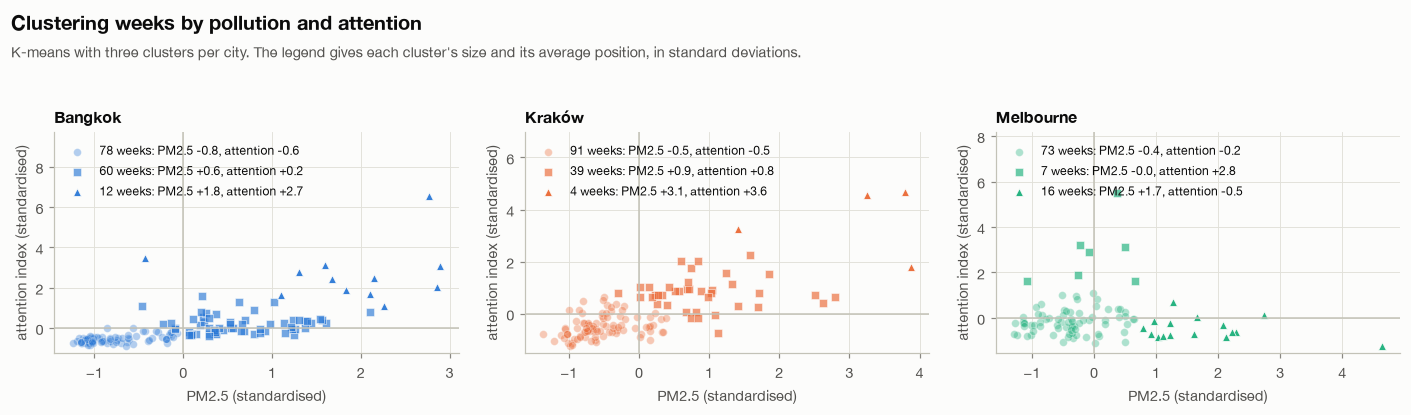

In [21]:
fig, clusters = P.regimes(long)

**Reading it.** Bangkok and Kraków weeks fall along one diagonal: quiet clean weeks, moderately polluted weeks with moderate attention, and a small group of very polluted weeks with very high attention. Melbourne is different in kind: one cluster has high attention without high pollution, and another has its most polluted weeks with below-average attention.

## Summary: what the EDA establishes

| Finding | Evidence | Consequence for the analysis |
|---|---|---|
| The PM2.5 record has gaps, some shared across cities | 1.1 | Use gap-aware methods; Melbourne results are provisional |
| Only local-language and purifier terms are dense | 1.2 | Headline series are local-language; mask terms dropped |
| PM2.5 is right-skewed with a few extreme weeks | 2.1–2.4 | Report rank-based statistics alongside Pearson |
| Both series share a strong annual cycle | 3.1–3.4 | Remove seasonality before claiming a relationship |
| Weeks are autocorrelated for about ten weeks | 3.3 | Significance tests must account for it |
| Search responds in the same week | 4.4 | No lag at weekly resolution |
| The relationship is not constant in time or in level | 4.1, 4.3 | Motivates studying when attention fails, not only whether it exists |
| Search terms share one underlying signal | 5.1–5.2 | Use a composite attention index |